In [1]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from tqdm.contrib.concurrent import process_map

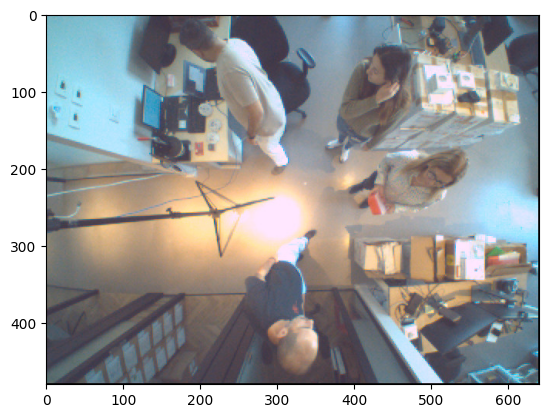

In [2]:
img = cv2.imread("quality_reduce_comparison/cam4_poc/images/val/4pplwalking-cam2.jpg")


plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))


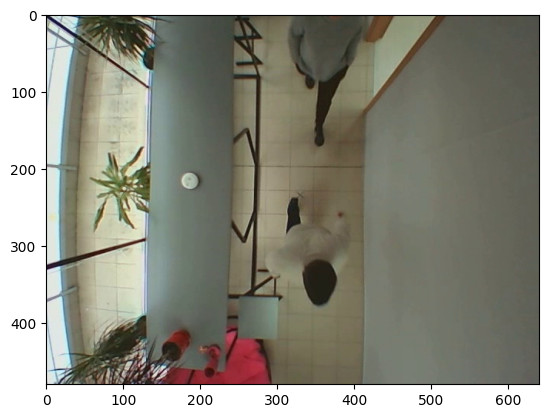

In [3]:
img_baseline = cv2.imread("../../../data/people_detection/filtered_v3_margin_15/images/holdout/2.12.21_H265_hall_3_N00003_10fps_00050.jpg")
plt.imshow(cv2.cvtColor(img_baseline, cv2.COLOR_BGR2RGB))

In [4]:
def gaussian_noise(img, mean, stddev, gamma = 1):
    #Create Gaussian Noise
    gauss_noise = np.zeros(img.shape[:2])
    cv2.randn(gauss_noise, mean, stddev)
    gauss_noise = (gauss_noise*gamma).astype(np.uint8)
    
    if len(img.shape) == 2:
        output = cv2.add(img, gauss_noise)
    elif len(img.shape) == 3:
        merged = cv2.merge([gauss_noise, gauss_noise, gauss_noise])
        output = cv2.add(img, merged)
    return output

def gasuss_noise(image, mu=0.0, sigma=0.1):
    """
     添加高斯噪声
    :param image: 输入的图像
    :param mu: 均值
    :param sigma: 标准差
    :return: 含有高斯噪声的图像
    """
    image = np.array(image / 255, dtype=float)
    noise = np.random.normal(mu, sigma, image.shape)
    gauss_noise = image + noise
    if gauss_noise.min() < 0:
        low_clip = -1.
    else:
        low_clip = 0.
    gauss_noise = np.clip(gauss_noise, low_clip, 1.0)
    gauss_noise = np.uint8(gauss_noise * 255)
    return gauss_noise


def salt_pepper_noise(img, prob = 0.5):
    '''
    Add salt and pepper noise to image
    prob: Probability of the noise
    '''
    output = img.copy()
    sp_noise = np.zeros_like(img)
    if len(img.shape) == 2:
        black = 0
        white = 255            
    else:
        colorspace = img.shape[2]
        if colorspace == 3:  # RGB
            black = np.array([0, 0, 0], dtype='uint8')
            white = np.array([255, 255, 255], dtype='uint8')
        else:  # RGBA
            black = np.array([0, 0, 0, 255], dtype='uint8')
            white = np.array([255, 255, 255, 255], dtype='uint8')
    probs = np.random.random(output.shape[:2])
    output[probs < (prob / 2)] = black
    output[probs > 1 - (prob / 2)] = white
    sp_noise[probs < (prob / 2)] = black
    sp_noise[probs > 1 - (prob / 2)] = white
    return output


def uniform_noise(img, gamma=1):
    uni_noise = np.zeros(img.shape[:2])
    cv2.randu(uni_noise, 0, 256)
    uni_noise = (uni_noise * gamma).astype(np.uint8)
    
    if len(img.shape) == 2:
        output = cv2.add(img, uni_noise)
    elif len(img.shape) == 3:
        merged = cv2.merge([uni_noise, uni_noise, uni_noise])
        output = cv2.add(img, merged)
    return output

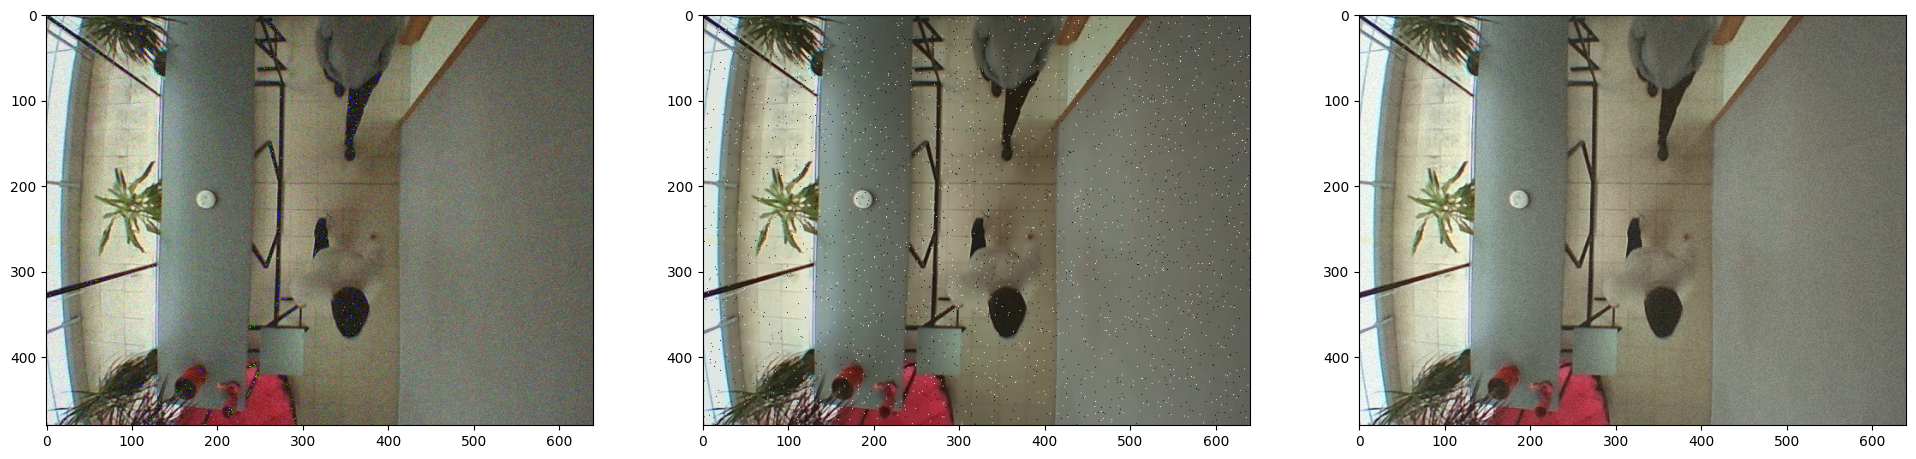

In [5]:
# img_gauss = gaussian_noise(img_baseline, 0, 0.3)
img_gauss = gasuss_noise(img_baseline, 0, 0.05)
img_salt_pepper = salt_pepper_noise(img_baseline, 0.01)
img_uniform = uniform_noise(img_baseline, 0.1)


plt.figure(figsize=(24, 10))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img_gauss, cv2.COLOR_BGR2RGB))

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_salt_pepper, cv2.COLOR_BGR2RGB))

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_uniform, cv2.COLOR_BGR2RGB))

# plt.tight_layout()

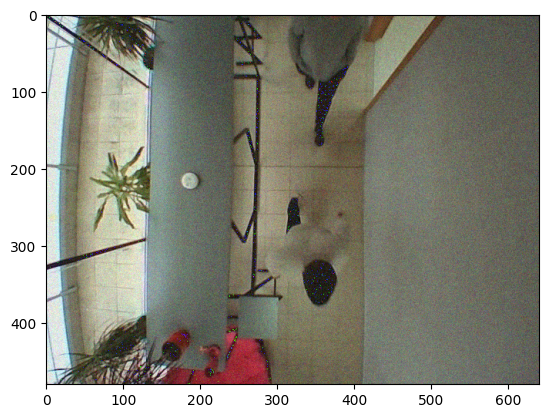

In [6]:
plt.imshow(cv2.cvtColor(img_gauss, cv2.COLOR_BGR2RGB))

In [10]:
def print_file_size(file):

    File_Size = os.path.getsize(file)
    File_Size_MB = round(File_Size/1024/1024,2)

    print(file, File_Size_MB)

In [13]:
cv2.imwrite("baseline.jpg", img_baseline)
cv2.imwrite("gauss.jpg", img_gauss, [cv2.IMWRITE_JPEG_QUALITY, 80])
cv2.imwrite("salt_pepper.jpg", img_salt_pepper, [cv2.IMWRITE_JPEG_QUALITY, 80])
cv2.imwrite("uniform.jpg", img_uniform, [cv2.IMWRITE_JPEG_QUALITY, 80])

print_file_size("baseline.jpg")
print_file_size("gauss.jpg")
print_file_size("salt_pepper.jpg")
print_file_size("uniform.jpg")

baseline.jpg 0.06
gauss.jpg 0.07
salt_pepper.jpg 0.07
uniform.jpg 0.06
